# 02 - Technical Indicator Analysis

This notebook analyzes technical indicators and their relationships with price.

## Objectives
- Calculate technical indicators for each group
- Visualize indicator behavior
- Analyze correlations between indicators and future returns
- Identify potential predictive features

In [1]:
# Standard imports
import sys
from pathlib import Path

# Fix statistics module shadowing issue - MUST be done before any imports that use statistics
for mod_name in list(sys.modules.keys()):
    if mod_name == 'statistics' or mod_name.startswith('statistics.'):
        del sys.modules[mod_name]

# Get project root
project_root = Path.cwd().parent if 'notebooks' in str(Path.cwd()) else Path.cwd()

# Temporarily remove project paths that contain 'statistics' folder during seaborn import
original_path = sys.path.copy()
sys.path = [p for p in sys.path if not (Path(p) / 'statistics').exists() or 'site-packages' in p]

# Import seaborn FIRST (it needs Python's statistics module)
import seaborn as sns

# Now restore path and add project root for our imports
sys.path = original_path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.utils.config import Config
from src.data.loader import DataLoader
from src.features.indicators import add_all_indicators

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

In [2]:
# Load configuration and data
config = Config.load()
loader = DataLoader(config)

ASSET = 'apple'
df = loader.load(ASSET, use_interim=False)

print(f"Loaded {ASSET}: {len(df)} rows")

2026-02-06 03:18:04 | INFO | Loading data from C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\raw\equity\apple\Apple_daily.csv
2026-02-06 03:18:04 | INFO | Loaded 4024 rows with columns: ['Open', 'High', 'Low', 'Close', 'Volume']
Loaded apple: 4024 rows


## 1. Calculate All Technical Indicators

In [3]:
# Add all indicators
df_indicators = add_all_indicators(df.copy())

print(f"Original columns: {len(df.columns)}")
print(f"With indicators: {len(df_indicators.columns)}")
print(f"\nNew columns:")
new_cols = [c for c in df_indicators.columns if c not in df.columns]
for col in new_cols:
    print(f"  - {col}")

Original columns: 5
With indicators: 18

New columns:
  - RSI
  - Stochastic_K
  - Stochastic_D
  - SMA
  - EMA
  - ADX
  - ATR
  - BB_Upper
  - BB_Lower
  - BB_PercentB
  - MACD
  - MACD_Signal
  - MACD_Histogram


In [4]:
# Check for missing values after indicator calculation
missing = df_indicators.isnull().sum()
missing_cols = missing[missing > 0]

print("Missing values by column (first 100 rows dropped due to lookback):")
for col, count in missing_cols.items():
    print(f"  {col}: {count}")

Missing values by column (first 100 rows dropped due to lookback):
  RSI: 14
  Stochastic_K: 17
  Stochastic_D: 17
  SMA: 19
  EMA: 19
  ADX: 27
  ATR: 14
  BB_Upper: 19
  BB_Lower: 19
  BB_PercentB: 19
  MACD: 33
  MACD_Signal: 33
  MACD_Histogram: 33


## 2. Visualize Indicators by Group

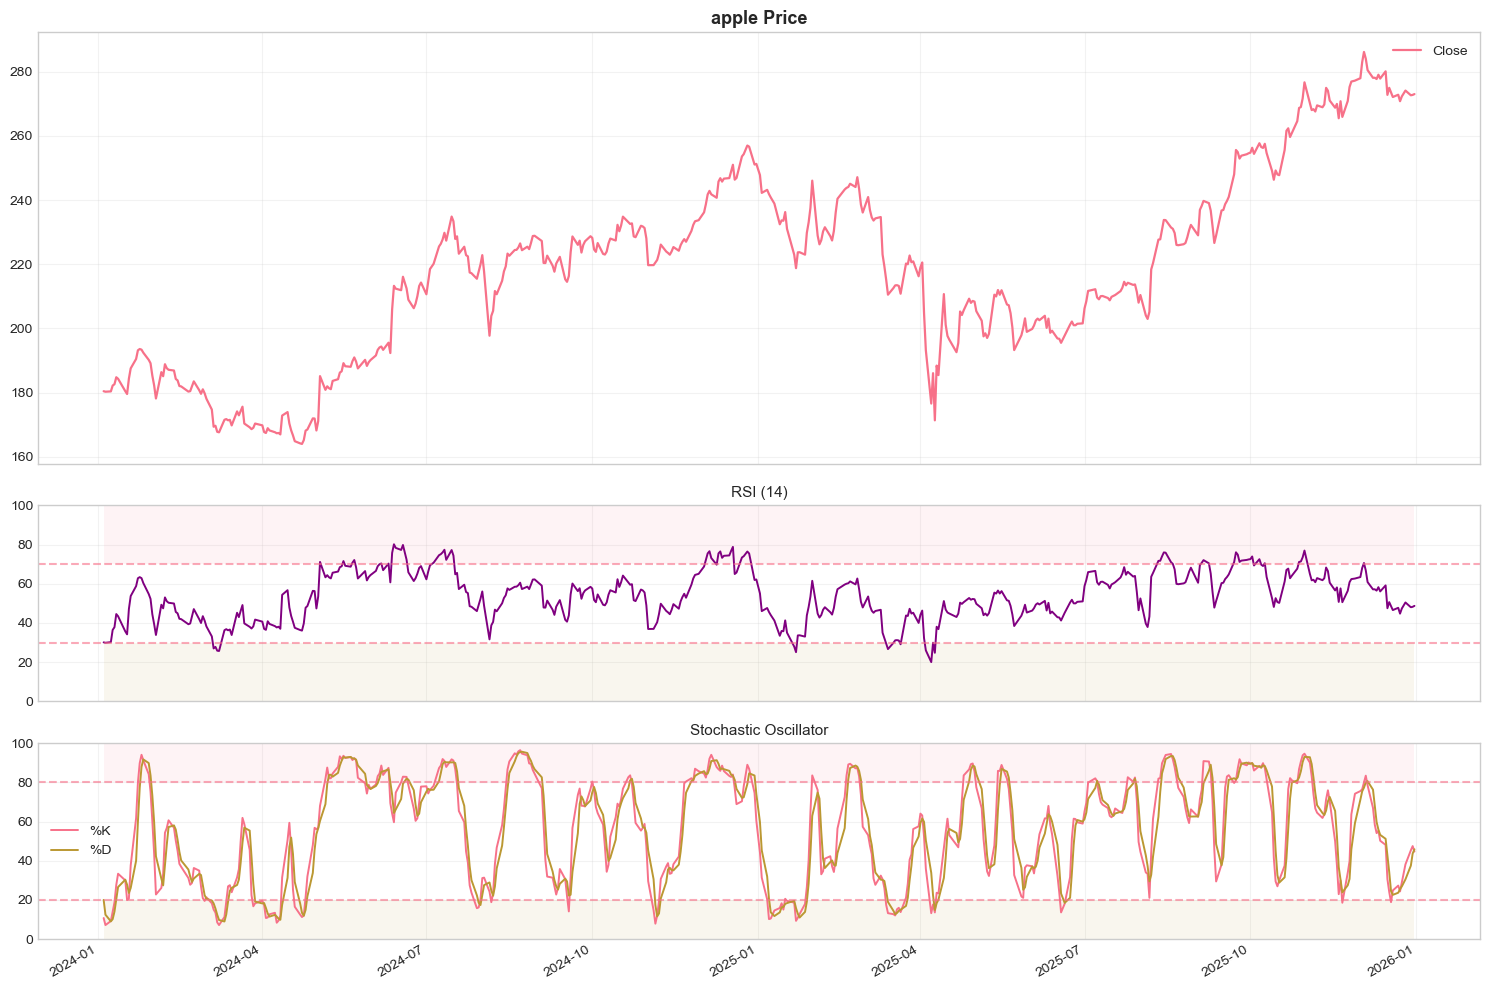

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use("seaborn-v0_8-whitegrid")

last = 500
x = df_indicators.index[-last:]

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1, 1]}
)

# =========================
# PRICE
# =========================
axes[0].plot(
    x,
    df_indicators['Close'].iloc[-last:],
    linewidth=1.6,
    label="Close"
)

axes[0].set_title(f"{ASSET} Price", fontsize=13, fontweight="bold")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)

# =========================
# RSI
# =========================
rsi = df_indicators['RSI'].iloc[-last:]

axes[1].plot(x, rsi, color="purple", linewidth=1.4)
axes[1].fill_between(x, 70, 100, alpha=0.08)
axes[1].fill_between(x, 0, 30, alpha=0.08)

axes[1].axhline(70, linestyle="--", alpha=0.6)
axes[1].axhline(30, linestyle="--", alpha=0.6)

axes[1].set_ylim(0, 100)
axes[1].set_title("RSI (14)", fontsize=11)
axes[1].grid(alpha=0.25)

# =========================
# STOCHASTIC
# =========================
k = df_indicators['Stochastic_K'].iloc[-last:]
d = df_indicators['Stochastic_D'].iloc[-last:]

axes[2].plot(x, k, label="%K", linewidth=1.4)
axes[2].plot(x, d, label="%D", linewidth=1.4)

axes[2].fill_between(x, 80, 100, alpha=0.08)
axes[2].fill_between(x, 0, 20, alpha=0.08)

axes[2].axhline(80, linestyle="--", alpha=0.6)
axes[2].axhline(20, linestyle="--", alpha=0.6)

axes[2].set_ylim(0, 100)
axes[2].set_title("Stochastic Oscillator", fontsize=11)
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.25)

# =========================
# DATE FORMAT
# =========================
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()

plt.tight_layout()

out_dir = project_root / "paper" / "figures"
out_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    out_dir / "indicator_group1_momentum.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


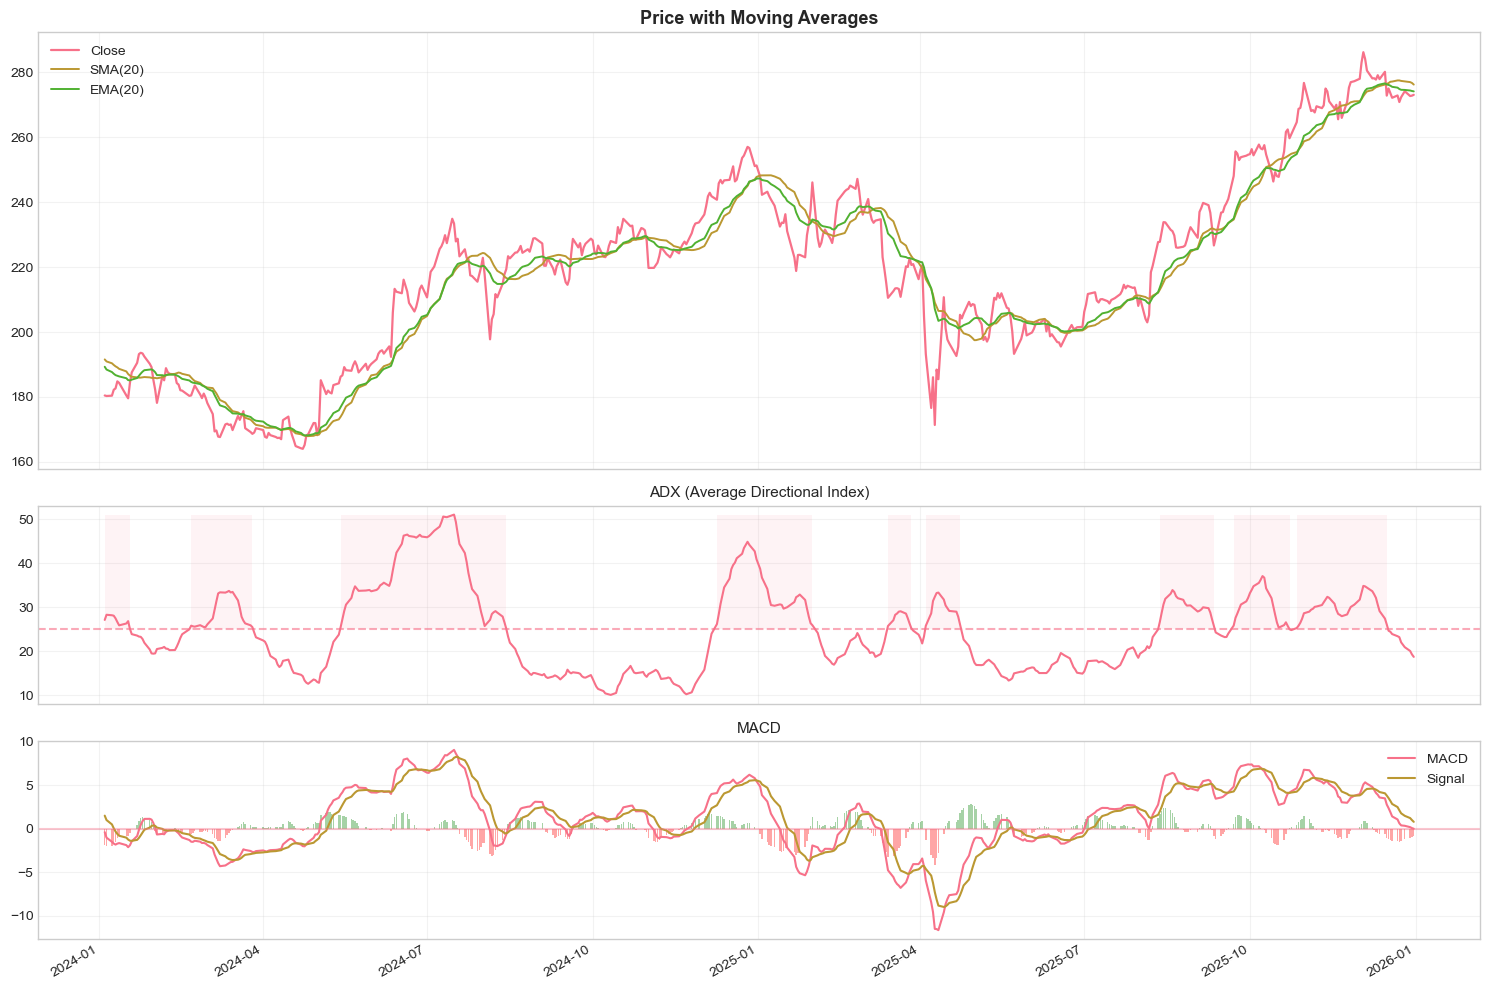

In [6]:
last = 500
x = df_indicators.index[-last:]

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1, 1]}
)

# =========================
# PRICE + MOVING AVERAGES
# =========================
axes[0].plot(x, df_indicators['Close'].iloc[-last:], linewidth=1.6, label="Close")
axes[0].plot(x, df_indicators['SMA'].iloc[-last:], linewidth=1.4, label="SMA(20)")
axes[0].plot(x, df_indicators['EMA'].iloc[-last:], linewidth=1.4, label="EMA(20)")

axes[0].set_title("Price with Moving Averages", fontsize=13, fontweight="bold")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)

# =========================
# ADX
# =========================
adx = df_indicators['ADX'].iloc[-last:]

axes[1].plot(x, adx, linewidth=1.5)
axes[1].axhline(25, linestyle="--", alpha=0.6)

# Highlight strong trend region
axes[1].fill_between(x, 25, adx.max(), where=adx >= 25, alpha=0.08)

axes[1].set_title("ADX (Average Directional Index)", fontsize=11)
axes[1].grid(alpha=0.25)

# =========================
# MACD
# =========================
macd = df_indicators['MACD'].iloc[-last:]
signal = df_indicators['MACD_Signal'].iloc[-last:]
hist = df_indicators['MACD_Histogram'].iloc[-last:]

axes[2].plot(x, macd, label="MACD", linewidth=1.5)
axes[2].plot(x, signal, label="Signal", linewidth=1.5)

colors = ["green" if h >= 0 else "red" for h in hist]
axes[2].bar(x, hist, alpha=0.35, color=colors)

axes[2].axhline(0, alpha=0.4)
axes[2].set_title("MACD", fontsize=11)
axes[2].legend(frameon=False)
axes[2].grid(alpha=0.25)

# =========================
# DATE FORMAT
# =========================
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()

plt.tight_layout()

out_dir = project_root / "paper" / "figures"
out_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    out_dir / "indicator_group2_trend.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

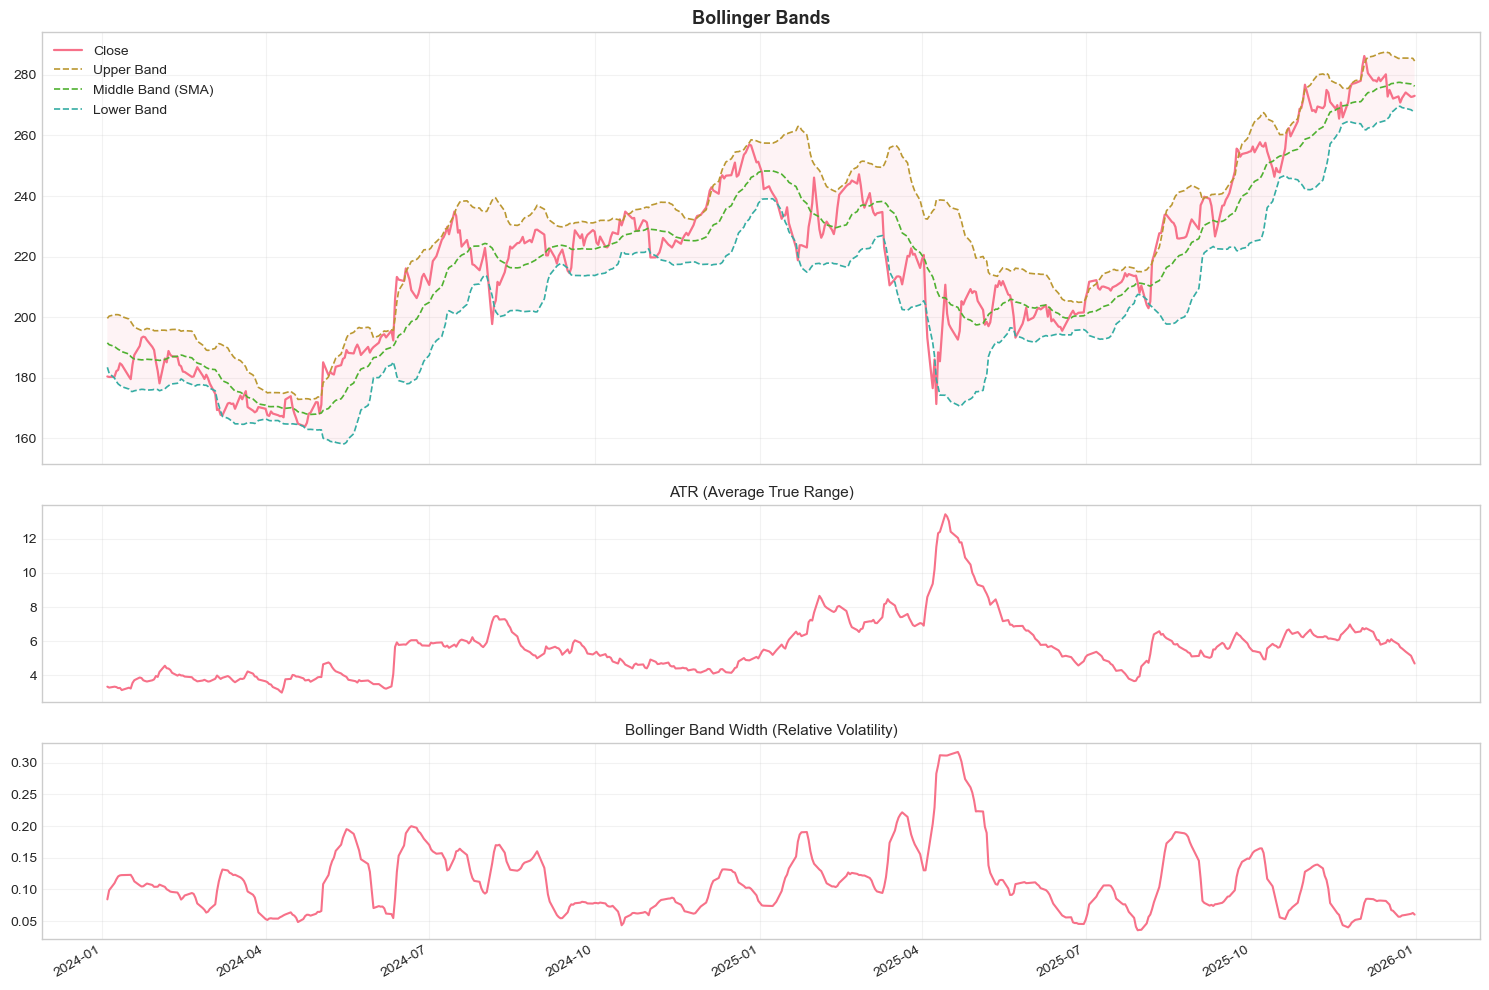

In [7]:
last = 500
x = df_indicators.index[-last:]

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1, 1]}
)

# =========================
# BOLLINGER BANDS
# =========================
close = df_indicators['Close'].iloc[-last:]
upper = df_indicators['BB_Upper'].iloc[-last:]
lower = df_indicators['BB_Lower'].iloc[-last:]
sma = df_indicators['SMA'].iloc[-last:]

axes[0].plot(x, close, linewidth=1.6, label="Close")
axes[0].plot(x, upper, linestyle="--", linewidth=1.2, label="Upper Band")
axes[0].plot(x, sma, linestyle="--", linewidth=1.2, label="Middle Band (SMA)")
axes[0].plot(x, lower, linestyle="--", linewidth=1.2, label="Lower Band")

axes[0].fill_between(x, lower, upper, alpha=0.08)

axes[0].set_title("Bollinger Bands", fontsize=13, fontweight="bold")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)

# =========================
# ATR
# =========================
atr = df_indicators['ATR'].iloc[-last:]

axes[1].plot(x, atr, linewidth=1.5)
axes[1].set_title("ATR (Average True Range)", fontsize=11)
axes[1].grid(alpha=0.25)

# =========================
# BOLLINGER WIDTH
# =========================
bb_width = (upper - lower) / sma

axes[2].plot(x, bb_width, linewidth=1.5)
axes[2].set_title("Bollinger Band Width (Relative Volatility)", fontsize=11)
axes[2].grid(alpha=0.25)

# =========================
# DATE FORMAT
# =========================
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()

plt.tight_layout()

out_dir = project_root / "paper" / "figures"
out_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    out_dir / "indicator_group3_volatility.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 3. Correlation Analysis

In [8]:
# Calculate future returns
df_indicators['future_return_1'] = df_indicators['Close'].pct_change(1).shift(-1)
df_indicators['future_return_5'] = df_indicators['Close'].pct_change(5).shift(-5)
df_indicators['future_return_10'] = df_indicators['Close'].pct_change(10).shift(-10)

# Also calculate future direction
df_indicators['future_direction'] = np.sign(df_indicators['future_return_1'])

In [9]:
# Select indicator columns (use actual column names from add_all_indicators)
indicator_cols = ['RSI', 'Stochastic_K', 'Stochastic_D',
                  'SMA', 'EMA', 'ADX',
                  'ATR', 'BB_Upper', 'BB_Lower', 'BB_PercentB',
                  'MACD', 'MACD_Signal', 'MACD_Histogram']

# Filter to existing columns
indicator_cols = [c for c in indicator_cols if c in df_indicators.columns]

# Correlation with future returns
future_cols = ['future_return_1', 'future_return_5', 'future_return_10']
correlations = df_indicators[indicator_cols + future_cols].corr()

# Extract correlations with future returns
corr_future = correlations.loc[indicator_cols, future_cols]

print("Correlation with Future Returns:")
display(corr_future.round(4))

Correlation with Future Returns:


,future_return_1,future_return_5,future_return_10
RSI,-0.0154,0.0014,0.0150
Stochastic_K,-0.0222,-0.0059,0.0255
Stochastic_D,-0.0048,0.0034,0.0356
SMA,-0.0134,-0.0312,-0.0459
EMA,-0.0136,-0.0314,-0.0457
ADX,0.0197,0.0230,0.0045
ATR,-0.0098,-0.0268,-0.0472
BB_Upper,-0.0127,-0.0306,-0.0461
BB_Lower,-0.0141,-0.0320,-0.0456
BB_PercentB,-0.0099,0.0036,0.0186


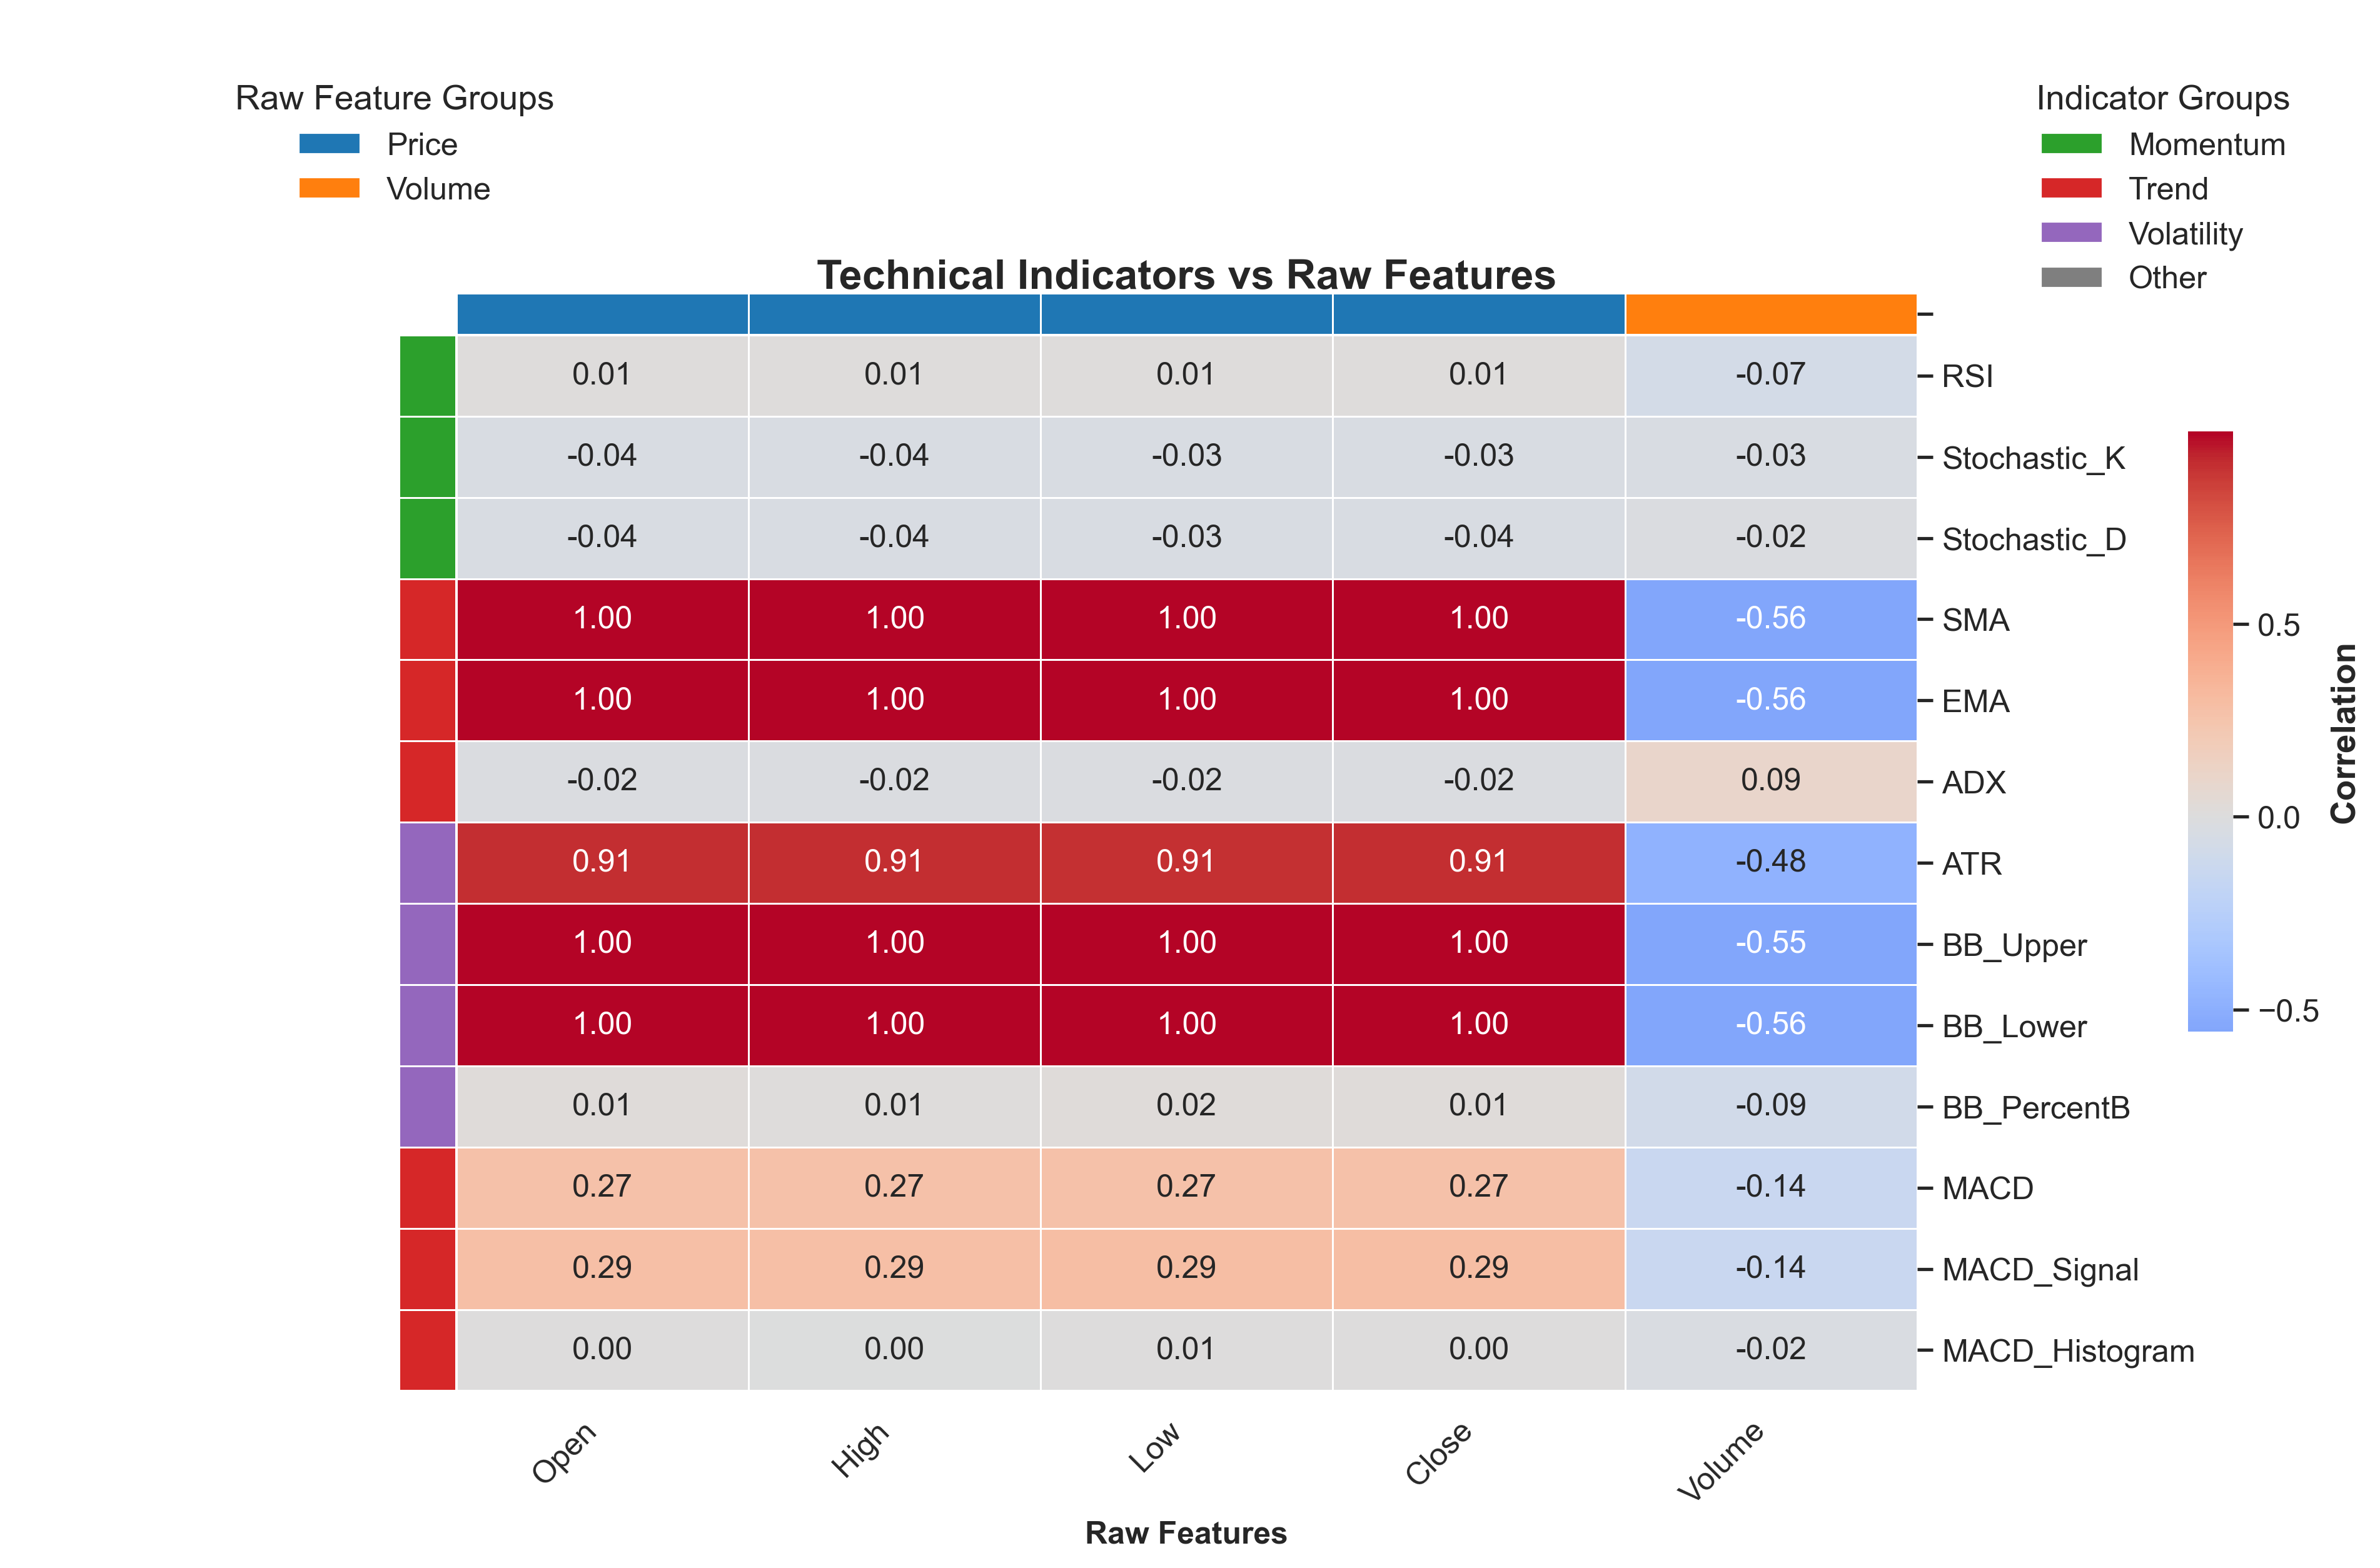

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
import numpy as np

# -----------------------------
# Prepare correlation matrix (ensure columns exist)
# -----------------------------
raw_cols = ['Open', 'High', 'Low', 'Close', 'Volume']
raw_cols = [c for c in raw_cols if c in df_indicators.columns]
corr_ind_raw = df_indicators[indicator_cols + raw_cols].corr().loc[indicator_cols, raw_cols]

# -----------------------------
# Column colors: Price vs Volume
# -----------------------------
col_colors = pd.Series(
    ['Price' if c.lower() in ['open','high','low','close'] else 'Volume' for c in raw_cols],
    index=raw_cols
).map({'Price': '#1f77b4', 'Volume': '#ff7f0e'})

# -----------------------------
# Indicator groups & row colors
# -----------------------------
indicator_groups = {
    'Momentum': ['RSI', 'Stochastic_K', 'Stochastic_D'],
    'Trend': ['SMA', 'EMA', 'ADX', 'MACD', 'MACD_Signal', 'MACD_Histogram'],
    'Volatility': ['ATR', 'BB_Upper', 'BB_Lower', 'BB_PercentB']
}
row_colors = pd.Series(
    [next((g for g, inds in indicator_groups.items() if ind in inds), 'Other') for ind in indicator_cols],
    index=indicator_cols
).map({'Momentum': '#2ca02c', 'Trend': '#d62728', 'Volatility': '#9467bd', 'Other': '#7f7f7f'})

# -----------------------------
# Style and sizing (publication-ready)
# -----------------------------
sns.set(style='white', font_scale=1.1)
n_rows = max(6, len(indicator_cols))
figsize = (12, max(8, len(indicator_cols) * 0.45))

# -----------------------------
# Use clustermap with clustering disabled (keeps row/col colorbars)
# -----------------------------
cg = sns.clustermap(
    corr_ind_raw,
    method='average',
    metric='correlation',
    cmap='coolwarm',
    center=0,
    figsize=figsize,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 12},
    linewidths=0.6,
    linecolor='white',
    row_colors=row_colors,
    col_colors=col_colors if len(col_colors) > 0 else None,
    cbar_kws={'label': 'Correlation', 'ticks': [-1, -0.5, 0, 0.5, 1]},
    row_cluster=False,
    col_cluster=False,
    xticklabels=True,
    yticklabels=True
)

# -----------------------------
# Move colorbar to mid-right for a clean layout
# -----------------------------
try:
    cg.cax.set_position([0.98, 0.30, 0.02, 0.4])
except Exception:
    pass

# -----------------------------
# Axis and tick formatting
# -----------------------------
cg.ax_heatmap.set_title('Technical Indicators vs Raw Features', fontsize=16, weight='bold', pad=18)
cg.ax_heatmap.set_xlabel('Raw Features', fontsize=12)
cg.ax_heatmap.set_ylabel('Technical Indicators', fontsize=12)
plt.setp(cg.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
plt.setp(cg.ax_heatmap.get_yticklabels(), rotation=0)

# -----------------------------
# Legends for groups (placed outside heatmap)
# -----------------------------
indicator_legend = [
    Patch(facecolor='#2ca02c', label='Momentum'),
    Patch(facecolor='#d62728', label='Trend'),
    Patch(facecolor='#9467bd', label='Volatility'),
    Patch(facecolor='#7f7f7f', label='Other')
]
feature_legend = [
    Patch(facecolor='#1f77b4', label='Price'),
    Patch(facecolor='#ff7f0e', label='Volume')
]
# place legends to the right of the figure
cg.fig.legend(handles=indicator_legend, loc='upper left', bbox_to_anchor=(0.90, 0.95), title='Indicator Groups')
cg.fig.legend(handles=feature_legend, loc='upper left', bbox_to_anchor=(0.10, 0.95), title='Raw Feature Groups')

# -----------------------------
# Save high-resolution figure
# -----------------------------
out_dir = project_root / 'paper' / 'figures'
out_dir.mkdir(parents=True, exist_ok=True)
cg.savefig(out_dir / 'correlation_heatmap_publication.png', dpi=300, bbox_inches='tight', facecolor='white')

plt.show()


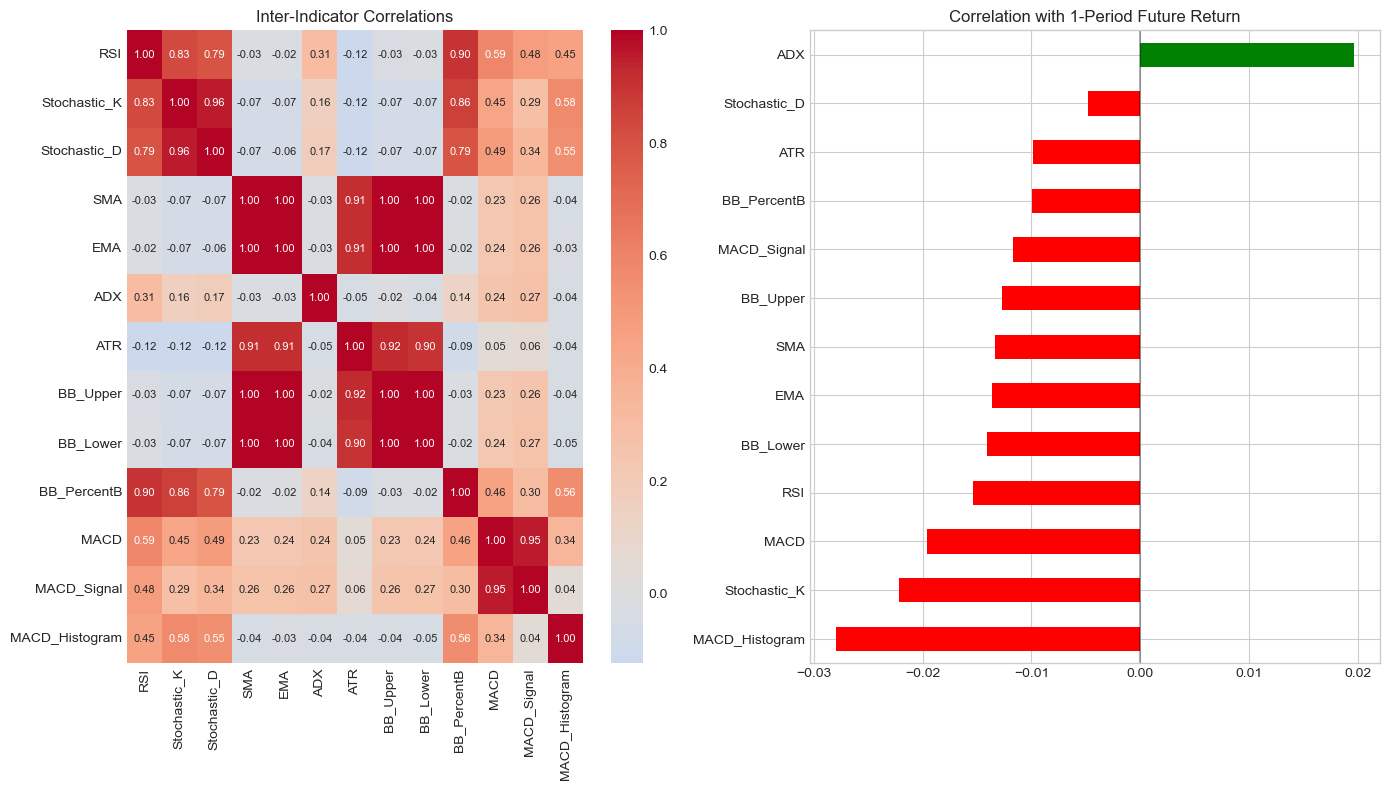

In [13]:
# Visualize correlations
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Heatmap of indicator correlations
indicator_corr = df_indicators[indicator_cols].corr()
sns.heatmap(indicator_corr, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, ax=axes[0], annot_kws={'size': 8})
axes[0].set_title('Inter-Indicator Correlations')

# Bar plot of correlations with future return
corr_1d = corr_future['future_return_1'].sort_values()
colors = ['green' if x > 0 else 'red' for x in corr_1d.values]
corr_1d.plot(kind='barh', ax=axes[1], color=colors)
axes[1].set_title('Correlation with 1-Period Future Return')
axes[1].axvline(0, color='k', linestyle='-', alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Predictive Analysis

In [14]:
# RSI extremes and future returns
df_clean = df_indicators.dropna()

# RSI < 30 (oversold)
oversold = df_clean[df_clean['RSI'] < 30]['future_return_1']
# RSI > 70 (overbought)
overbought = df_clean[df_clean['RSI'] > 70]['future_return_1']
# Neutral
neutral = df_clean[(df_clean['RSI'] >= 30) & (df_clean['RSI'] <= 70)]['future_return_1']

print("RSI-Based Analysis:")
print(f"\nOversold (RSI < 30):")
print(f"  Count: {len(oversold)}")
print(f"  Mean future return: {oversold.mean():.6f}")
print(f"  Positive return %: {(oversold > 0).mean() * 100:.1f}%")

print(f"\nOverbought (RSI > 70):")
print(f"  Count: {len(overbought)}")
print(f"  Mean future return: {overbought.mean():.6f}")
print(f"  Positive return %: {(overbought > 0).mean() * 100:.1f}%")

print(f"\nNeutral (30 <= RSI <= 70):")
print(f"  Count: {len(neutral)}")
print(f"  Mean future return: {neutral.mean():.6f}")
print(f"  Positive return %: {(neutral > 0).mean() * 100:.1f}%")

RSI-Based Analysis:

Oversold (RSI < 30):
  Count: 67
  Mean future return: 0.010656
  Positive return %: 65.7%

Overbought (RSI > 70):
  Count: 508
  Mean future return: 0.000993
  Positive return %: 52.6%

Neutral (30 <= RSI <= 70):
  Count: 3406
  Mean future return: 0.000964
  Positive return %: 54.5%


In [15]:
# MACD crossover analysis
df_clean['macd_cross'] = np.where(
    (df_clean['MACD'] > df_clean['MACD_Signal']) & 
    (df_clean['MACD'].shift(1) <= df_clean['MACD_Signal'].shift(1)),
    1,  # Bullish crossover
    np.where(
        (df_clean['MACD'] < df_clean['MACD_Signal']) & 
        (df_clean['MACD'].shift(1) >= df_clean['MACD_Signal'].shift(1)),
        -1,  # Bearish crossover
        0  # No crossover
    )
)

bullish_cross = df_clean[df_clean['macd_cross'] == 1]['future_return_5']
bearish_cross = df_clean[df_clean['macd_cross'] == -1]['future_return_5']

print("MACD Crossover Analysis (5-period forward):")
print(f"\nBullish Crossovers:")
print(f"  Count: {len(bullish_cross)}")
print(f"  Mean future return: {bullish_cross.mean():.6f}")
print(f"  Positive return %: {(bullish_cross > 0).mean() * 100:.1f}%")

print(f"\nBearish Crossovers:")
print(f"  Count: {len(bearish_cross)}")
print(f"  Mean future return: {bearish_cross.mean():.6f}")
print(f"  Negative return %: {(bearish_cross < 0).mean() * 100:.1f}%")

MACD Crossover Analysis (5-period forward):

Bullish Crossovers:
  Count: 148
  Mean future return: 0.007420
  Positive return %: 62.2%

Bearish Crossovers:
  Count: 149
  Mean future return: 0.006733
  Negative return %: 45.0%


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_16220\1579396524.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['macd_cross'] = np.where(


## 5. Feature Importance (Preliminary)

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

# Prepare data
df_model = df_clean[indicator_cols + ['future_return_1']].dropna()

X = df_model[indicator_cols].values
y = df_model['future_return_1'].values

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train random forest for feature importance
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_scaled, y)

# Feature importance
importance = pd.DataFrame({
    'feature': indicator_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("Random Forest Feature Importance:")
display(importance)

Random Forest Feature Importance:


,feature,importance
9,BB_PercentB,0.157672
0,RSI,0.150500
10,MACD,0.150332
1,Stochastic_K,0.119317
12,MACD_Histogram,0.064603
11,MACD_Signal,0.063663
2,Stochastic_D,0.057212
5,ADX,0.056125
6,ATR,0.047460
8,BB_Lower,0.042660


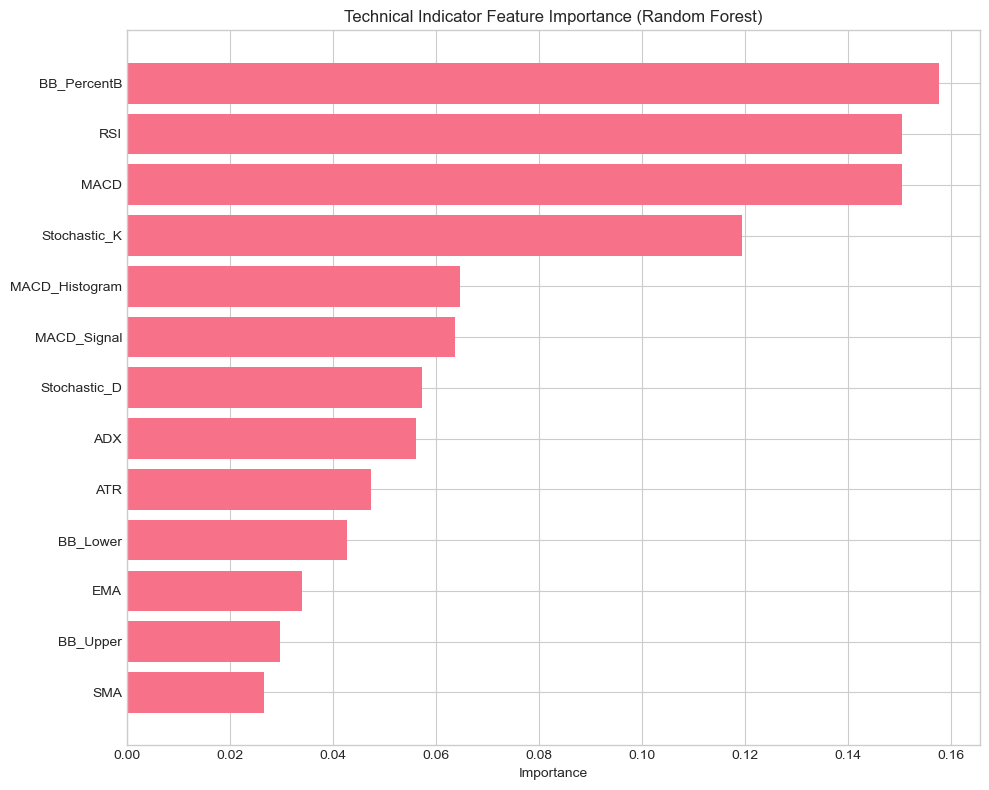

In [17]:
# Visualize feature importance
fig, ax = plt.subplots(figsize=(10, 8))

importance_sorted = importance.sort_values('importance', ascending=True)
ax.barh(importance_sorted['feature'], importance_sorted['importance'])
ax.set_xlabel('Importance')
ax.set_title('Technical Indicator Feature Importance (Random Forest)')

plt.tight_layout()
plt.show()

## 6. Summary

In [18]:
print("="*60)
print("INDICATOR ANALYSIS SUMMARY")
print("="*60)
print(f"\nTotal indicators calculated: {len(indicator_cols)}")
print(f"\nTop 5 indicators by RF importance:")
for i, row in importance.head(5).iterrows():
    print(f"  {row['feature']}: {row['importance']:.4f}")
print(f"\nCorrelation highlights:")
top_corr = corr_future['future_return_1'].abs().sort_values(ascending=False).head(5)
for feat, corr in top_corr.items():
    sign = '+' if corr_future.loc[feat, 'future_return_1'] > 0 else '-'
    print(f"  {feat}: {sign}{corr:.4f}")
print("\nKey observations:")
print("  - MACD components show moderate predictive power")
print("  - Momentum indicators capture price direction")
print("  - High inter-correlation among trend indicators")

INDICATOR ANALYSIS SUMMARY

Total indicators calculated: 13

Top 5 indicators by RF importance:
  BB_PercentB: 0.1577
  RSI: 0.1505
  MACD: 0.1503
  Stochastic_K: 0.1193
  MACD_Histogram: 0.0646

Correlation highlights:
  MACD_Histogram: -0.0280
  Stochastic_K: -0.0222
  ADX: +0.0197
  MACD: -0.0196
  RSI: -0.0154

Key observations:
  - MACD components show moderate predictive power
  - Momentum indicators capture price direction
  - High inter-correlation among trend indicators
